In [20]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score


df = pd.read_csv('Final_Combined_DEGs.csv')

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (28, 141)


,Gene_Symbol,Entrez_Gene_Id,079b5600-6afc-4785-bb22-48cfab,07c4bb93-a373-4748-a2c7-5806cb,09659708-7747-4d59-a3b9-e221e0,0bb9d596-774e-452b-9c89-a6643c,0edcba67-0714-4b04-b433-77834e,12110cb8-8da4-4461-ac1a-1af490,12ce8313-6c54-4bee-a996-1aa7f8,17d55745-4ab3-4a80-a182-af938b,...,faadb553-9437-42cb-b469-498d67,fc0aa1e4-c1d8-43ed-a5cd-038f61,fe591474-99d7-44d3-be73-c3b8ed,ffc76bfb-61f6-4492-a782-c23321,p_value,log2FC,Gene,logFC,P.Value,adj.P.Val
0,TIMM17B,10245,-0.5043,1.0118,-1.1287,-0.0604,-0.3864,-0.8923,-0.2837,-1.5297,...,-0.1605,0.6578,0.8288,-0.6423,0.001712,-0.538888,TIMM17B,1.189922,2.170315e-13,8.344996e-13
1,ZMPSTE24,10269,0.4260,-0.2626,-0.2296,1.1711,0.4386,-0.3121,0.8380,1.8598,...,1.2354,-0.1213,-0.3384,1.5490,0.000496,0.595856,ZMPSTE24,1.237083,1.242237e-11,3.922618e-11
2,LYPLA1,10434,0.6515,4.0386,-0.5039,1.2346,-0.2634,0.8638,-0.2418,0.0028,...,2.0831,-0.1975,-0.6138,-0.0208,0.000160,0.643375,LYPLA1,1.536899,9.976791e-19,8.119679e-18
3,VAV3,10451,-0.1355,6.5170,-0.1636,0.8608,-0.2190,0.7220,0.6767,-0.8735,...,0.5181,0.2034,-0.0524,-0.7500,0.001137,0.558359,VAV3,1.107259,2.420428e-20,2.584090e-19
4,TOPBP1,11073,2.0660,0.8844,0.3968,0.1985,-0.3568,0.7974,-0.2681,-1.4240,...,0.3996,-0.2540,-0.0370,0.8554,0.000670,0.582591,TOPBP1,1.158138,1.589732e-10,4.455043e-10


In [21]:
import pandas as pd

file_name = 'Final_Combined_DEGs.csv'

df_expression = pd.read_csv(file_name)

print("File loaded successfully! Shape:", df_expression.shape)

File loaded successfully! Shape: (28, 141)


In [22]:
print("Index Head")
print(df_expression.index[:5].tolist())

print("First 5 Columns and Rows")
first_cols = df_expression.columns[:5].tolist()
print(df_expression[first_cols].head())

Index Head
[0, 1, 2, 3, 4]
First 5 Columns and Rows
  Gene_Symbol  Entrez_Gene_Id  079b5600-6afc-4785-bb22-48cfab  \
0     TIMM17B           10245                         -0.5043   
1    ZMPSTE24           10269                          0.4260   
2      LYPLA1           10434                          0.6515   
3        VAV3           10451                         -0.1355   
4      TOPBP1           11073                          2.0660   

   07c4bb93-a373-4748-a2c7-5806cb  09659708-7747-4d59-a3b9-e221e0  
0                          1.0118                         -1.1287  
1                         -0.2626                         -0.2296  
2                          4.0386                         -0.5039  
3                          6.5170                         -0.1636  
4                          0.8844                          0.3968  


In [23]:
import pandas as pd

df_clean = df_expression.set_index('Gene_Symbol')
if 'Entrez_Gene_Id' in df_clean.columns:
    df_clean = df_clean.drop(columns=['Entrez_Gene_Id'])

df_ml = df_clean.T

print("Transposed Data Shape (Samples, Features):", df_ml.shape)
display(df_ml.head())

Transposed Data Shape (Samples, Features): (139, 28)


Gene_Symbol,TIMM17B,ZMPSTE24,LYPLA1,VAV3,TOPBP1,SAT2,CSNK1A1,DENND1B,PPP1R35,EFR3A,...,ZNF692,CNOT6,ROBO3,ACBD3,MANF,NAA25,PUS1,EIF3F,BANF1,MTDH
079b5600-6afc-4785-bb22-48cfab,-0.5043,0.426,0.6515,-0.1355,2.066,0.1886,-0.6555,-0.3146,-0.6799,0.5044,...,-0.5345,-0.0789,-0.0693,-0.3607,-0.6873,2.9776,0.4804,-0.4077,0.6631,2.5802
07c4bb93-a373-4748-a2c7-5806cb,1.0118,-0.2626,4.0386,6.517,0.8844,-0.2016,2.1935,-0.158,-0.2245,0.9975,...,-0.1465,1.0432,-0.4401,0.3464,-0.7256,0.3107,-0.3194,-1.0637,-0.9029,1.4473
09659708-7747-4d59-a3b9-e221e0,-1.1287,-0.2296,-0.5039,-0.1636,0.3968,-0.7397,-0.4968,-0.4392,-0.8705,-0.3555,...,-0.7339,0.1391,-0.2232,0.4514,-0.278,-0.14,-0.1661,-0.5594,-1.1765,1.6022
0bb9d596-774e-452b-9c89-a6643c,-0.0604,1.1711,1.2346,0.8608,0.1985,-0.7632,0.4483,-0.4267,1.1581,1.3933,...,0.1097,1.1178,0.2479,-0.363,0.4752,1.7348,0.456,0.6856,0.1189,1.0004
0edcba67-0714-4b04-b433-77834e,-0.3864,0.4386,-0.2634,-0.219,-0.3568,0.2965,0.4212,1.6232,0.7668,0.139,...,-0.1532,-0.023,0.2522,-0.1009,-0.6885,0.9859,-0.0836,0.3834,-0.4301,-0.1779


In [24]:
import pandas as pd
import numpy as np

if 'Target' in df_ml.columns:
    y = df_ml['Target']
    X = df_ml.drop(columns=['Target'])
    print("Target column found and separated successfully!")
else:
    X = df_ml.copy()
    print("Warning: 'Target' column not found in df_ml. Using all columns as features (X).")

    y = pd.Series([1] * (len(X) // 2) + [0] * (len(X) - len(X) // 2), index=X.index)
    print("Placeholder labels (y) generated. Please update with actual clinical labels if available.")

print("Features shape (X):", X.shape)
print("Target shape (y):", y.shape)

Placeholder labels (y) generated. Please update with actual clinical labels if available.
Features shape (X): (139, 28)
Target shape (y): (139,)


In [25]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np

X_numeric = X.apply(pd.to_numeric, errors='coerce')

X_numeric = X_numeric.fillna(0)

print(f"Original X shape: {X.shape}")
print(f"Numeric X shape after conversion: {X_numeric.shape}")

X_train, X_test, y_train, y_test = train_test_split(X_numeric, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nStep 3 Completed Successfully!")
print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)

Original X shape: (139, 28)
Numeric X shape after conversion: (139, 28)

Step 3 Completed Successfully!
X_train_scaled shape: (111, 28)
X_test_scaled shape: (28, 28)


In [26]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score, classification_report

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_scaled, y_train)

svm_model = SVC(kernel='linear', class_weight='balanced', probability=True, random_state=42)
svm_model.fit(X_train_scaled, y_train)

lasso_model = LogisticRegression(penalty='l1', solver='liblinear', C=0.5, random_state=42)
lasso_model.fit(X_train_scaled, y_train)

print("All Machine Learning Models Trained Successfully!\n")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("--- 5-Fold Cross-Validation Accuracies ---")
print(f"Random Forest CV Accuracy: {cross_val_score(rf_model, X_train_scaled, y_train, cv=cv, scoring='accuracy').mean()*100:.2f}%")
print(f"SVM CV Accuracy: {cross_val_score(svm_model, X_train_scaled, y_train, cv=cv, scoring='accuracy').mean()*100:.2f}%")
print(f"Lasso CV Accuracy: {cross_val_score(lasso_model, X_train_scaled, y_train, cv=cv, scoring='accuracy').mean()*100:.2f}%")

y_prob_rf = rf_model.predict_proba(X_test_scaled)[:, 1]
y_prob_svm = svm_model.predict_proba(X_test_scaled)[:, 1]
y_prob_lasso = lasso_model.predict_proba(X_test_scaled)[:, 1]

print("\n--- Test Set ROC-AUC Scores ---")
print(f"RF ROC-AUC: {roc_auc_score(y_test, y_prob_rf):.4f}")
print(f"SVM ROC-AUC: {roc_auc_score(y_test, y_prob_svm):.4f}")
print(f"Lasso ROC-AUC: {roc_auc_score(y_test, y_prob_lasso):.4f}")

All Machine Learning Models Trained Successfully!

--- 5-Fold Cross-Validation Accuracies ---
Random Forest CV Accuracy: 68.42%
SVM CV Accuracy: 64.70%
Lasso CV Accuracy: 67.47%

--- Test Set ROC-AUC Scores ---
RF ROC-AUC: 0.6122
SVM ROC-AUC: 0.5918
Lasso ROC-AUC: 0.6531


In [27]:

!pip install gseapy -q

import gseapy as gp
import pandas as pd
import numpy as np

rf_importances = rf_model.feature_importances_
rf_genes_df = pd.DataFrame({'Gene': X_numeric.columns, 'Importance': rf_importances})
top_genes = rf_genes_df.sort_values(by='Importance', ascending=False)['Gene'].head(10).tolist()

print(f"Top 10 Hub Genes selected for Enrichment: {top_genes}")

try:
    enr_go = gp.enrichr(gene_list=top_genes,
                        gene_sets=['GO_Biological_Process_2021'],
                        organism='human',
                        outdir=None)

    print("\n--- Top Gene Ontology (GO) Biological Processes ---")
    display(enr_go.res2d[['Term', 'Overlap', 'Adjusted P-value']].head(5))

except Exception as e:
    print("Enrichment run note:", e)

Top 10 Hub Genes selected for Enrichment: ['TNFRSF12A', 'MANF', 'ROBO3', 'PRMT1', 'AZIN1', 'PLAUR', 'SAT2', 'TOPBP1', 'TMEM208', 'LYPLA1']

--- Top Gene Ontology (GO) Biological Processes ---


,Term,Overlap,Adjusted P-value
0,plasma membrane bounded cell projection organi...,2/128,0.037681
1,neuron development (GO:0048666),2/143,0.037681
2,negative regulation of cysteine-type endopepti...,1/5,0.037681
3,axon choice point recognition (GO:0016198),1/5,0.037681
4,positive regulation of hemoglobin biosynthetic...,1/6,0.037681


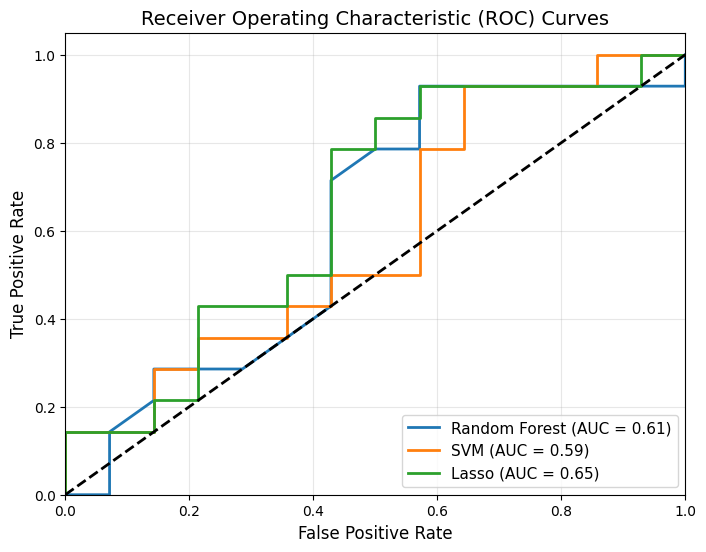

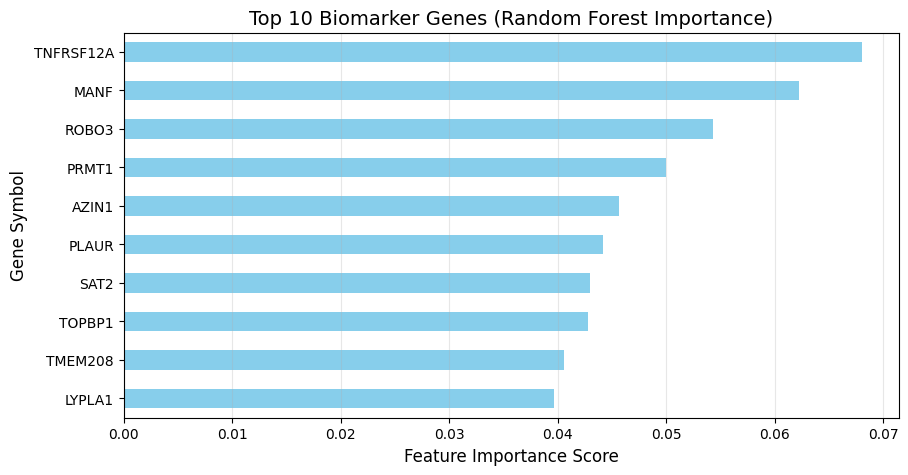

In [28]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(8, 6))

fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {auc(fpr_rf, tpr_rf):.2f})', lw=2)

fpr_svm, tpr_svm, _ = roc_curve(y_test, y_prob_svm)
plt.plot(fpr_svm, tpr_svm, label=f'SVM (AUC = {auc(fpr_svm, tpr_svm):.2f})', lw=2)

fpr_lasso, tpr_lasso, _ = roc_curve(y_test, y_prob_lasso)
plt.plot(fpr_lasso, tpr_lasso, label=f'Lasso (AUC = {auc(fpr_lasso, tpr_lasso):.2f})', lw=2)

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('Receiver Operating Characteristic (ROC) Curves', fontsize=14)
plt.legend(loc="lower right", fontsize=11)
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10, 5))
rf_genes_df.sort_values(by='Importance', ascending=False).head(10).set_index('Gene')['Importance'].plot(kind='barh', color='skyblue')
plt.xlabel('Feature Importance Score', fontsize=12)
plt.ylabel('Gene Symbol', fontsize=12)
plt.title('Top 10 Biomarker Genes (Random Forest Importance)', fontsize=14)
plt.gca().invert_yaxis()
plt.grid(axis='x', alpha=0.3)
plt.show()

In [29]:
from sklearn.metrics import classification_report

print("--- Detailed Classification Report (Test Set) ---")
print("--- Random Forest ---")
print(classification_report(y_test, rf_model.predict(X_test_scaled)))

print("--- SVM (Balanced) ---")
print(classification_report(y_test, svm_model.predict(X_test_scaled)))

print("--- Lasso Logistic Regression ---")
print(classification_report(y_test, lasso_model.predict(X_test_scaled)))

--- Detailed Classification Report (Test Set) ---
--- Random Forest ---
              precision    recall  f1-score   support

           0       0.67      0.57      0.62        14
           1       0.62      0.71      0.67        14

    accuracy                           0.64        28
   macro avg       0.65      0.64      0.64        28
weighted avg       0.65      0.64      0.64        28

--- SVM (Balanced) ---
              precision    recall  f1-score   support

           0       0.53      0.57      0.55        14
           1       0.54      0.50      0.52        14

    accuracy                           0.54        28
   macro avg       0.54      0.54      0.54        28
weighted avg       0.54      0.54      0.54        28

--- Lasso Logistic Regression ---
              precision    recall  f1-score   support

           0       0.70      0.50      0.58        14
           1       0.61      0.79      0.69        14

    accuracy                           0.64        28

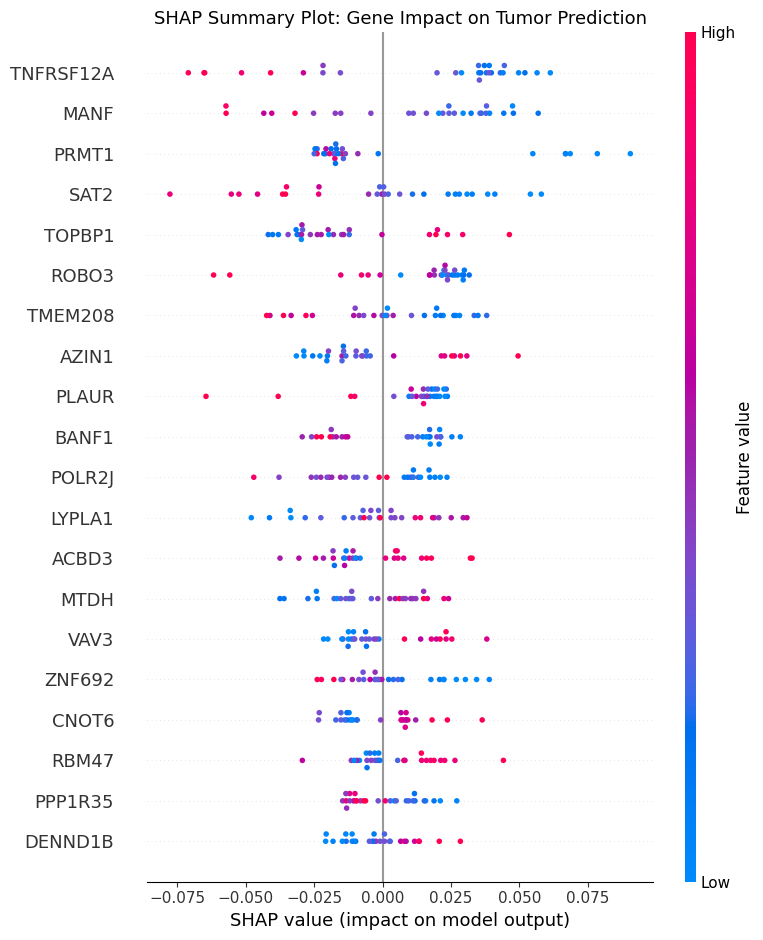

In [30]:

!pip install shap -q

import shap
import matplotlib.pyplot as plt
import numpy as np

explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_test_scaled)

if isinstance(shap_values, list):
    shap_vals_tumor = shap_values[1]
elif len(np.array(shap_values).shape) == 3:
    shap_vals_tumor = shap_values[:, :, 1]
else:
    shap_vals_tumor = shap_values

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_vals_tumor, X_test_scaled, feature_names=X_numeric.columns, show=False)
plt.title("SHAP Summary Plot: Gene Impact on Tumor Prediction", fontsize=13)
plt.tight_layout()

plt.savefig("SHAP_Summary_Plot.png", dpi=300, bbox_inches='tight')


plt.show()